[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmedelshazly27/mizan-kuwait-energy-toolkit/blob/main/notebooks/02-kuwaiti-inputs.ipynb)

In [1]:
# On Colab: clone the repository and install it (inputs are committed, no credentials needed).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("mizan-kuwait-energy-toolkit"):
    !git clone --depth 1 https://github.com/ahmedelshazly27/mizan-kuwait-energy-toolkit.git
    %pip install -q -e "mizan-kuwait-energy-toolkit[pv,econ,system]" matplotlib
    os.chdir("mizan-kuwait-energy-toolkit")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from kwtk import viz; viz.style()

# 2. The Kuwaiti inputs

Measured data come from the Kuwait Electricity Open Dataset, copied unchanged into
`inputs/dataset/` and pinned to a dataset commit. Loaders never choose between
sources: a series call names its source, and open conflicts are reported.

In [2]:
from kwtk.inputs import dataset as d
import yaml
print(yaml.safe_load(open('inputs/dataset/MANIFEST.yaml'))['commit'][:12], d.verify() or 'snapshot verified')

8438f4b27d09 snapshot verified


In [3]:
f = d.fleet('mew-yb-2023')
print(len(f), 'units,', f.capacity_mw.sum(), 'MW')
f.pivot_table(index='plant_id', columns='technology', values='capacity_mw', aggfunc='sum', fill_value=0).round(1)

117 units, 20250.0 MW


technology,csp,gas_cc,ocgt,pv,steam,steam_cc,wind
plant_id,,,,,,,
doha-east,0.0,0.0,72.0,0.0,1050.0,0.0,0.0
doha-west,0.0,0.0,141.0,0.0,2400.0,0.0,0.0
sabiya,0.0,2450.0,1000.2,0.0,2400.0,1196.5,0.0
shagaya,50.0,0.0,0.0,10.0,0.0,0.0,10.0
shuaiba-north,0.0,660.0,0.0,0.0,0.0,215.5,0.0
shuaiba-south,0.0,0.0,0.0,0.0,720.0,0.0,0.0
shuwaikh,0.0,0.0,252.0,0.0,0.0,0.0,0.0
zour-north,0.0,1130.0,0.0,0.0,0.0,502.0,0.0
zour-south,0.0,2300.0,110.8,0.0,2400.0,1180.0,0.0


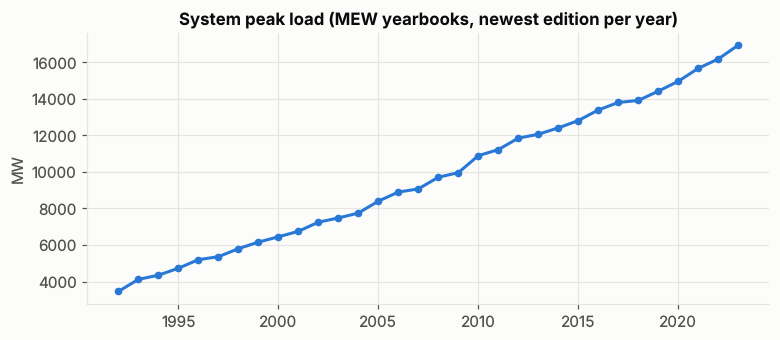

In [4]:
p = d.series('peak_load', 'national', 'annual', series='mew-yb')
p = p.sort_values('source_id').groupby('period_start').last()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(pd.to_datetime(p.index).year, p.value, marker='o', ms=4)
ax.set_title('System peak load (MEW yearbooks, newest edition per year)'); ax.set_ylabel('MW')
plt.show()

In [5]:
cap = d.series('installed_capacity', 'national', 'annual', series='mew-yb')
print(len(d.open_conflicts(cap.id)), 'open conflicts on national capacity (listed, not resolved):')
d.open_conflicts(cap.id)[['key', 'values']].head()

4 open conflicts on national capacity (listed, not resolved):


,key,values
0,installed_capacity national 1992-01-01..1992-1...,mew-yb-2020 capacity-history p52 [1992 / Total...
1,installed_capacity national 1998-01-01..1998-1...,mew-yb-2020 capacity-history p52 [1998 / Total...
2,installed_capacity national 1999-01-01..1999-1...,mew-yb-2020 capacity-history p52 [1999 / Total...
3,installed_capacity national 2019-01-01..2019-1...,mew-yb-2020 capacity-history p52 [2019 / Total...


In [6]:
pd.DataFrame(yaml.safe_load(open('inputs/assumptions.yaml'))['assumptions']).T[['value', 'unit', 'status']].fillna('')

,value,unit,status
albedo.desert,0.3,fraction,unverified
thermal.pvsyst_uc,29.0,W/m2K,proxy
thermal.pvsyst_uc_tracker,29.0,W/m2K,proxy
thermal.pvsyst_uv,0.0,W/m2K per m/s,proxy
layout.collector_width_1p,,m,open
soiling.kuwait_rate_by_month,"[0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.4...","% per day, Jan..Dec",unverified
soiling.rain_cleaning_threshold,6.0,mm per day,proxy
soiling.max_loss,30.0,%,proxy
cleaning.effectiveness,1.0,fraction,proxy
cleaning.cost,480.0,USD per MWp per cleaning,unverified
